# Mini Project 3: Fashion Item Recognition

## Can a CNN recognize clothes, and which design works best?

I build a classifier for the 10 clothing categories of **Fashion-MNIST** (T-shirt/top, trouser, pullover, dress, coat, sandal, shirt, sneaker, bag, ankle boot). I train **three CNN versions**, compare them in a table, choose the best one using validation data, and save it.

### Required output
| Requirement | Section |
|-------------|---------|
| Working notebook | the whole notebook |
| Comparison table | Part 3 |
| Prediction gallery | Part 5 |
| Saved model | Part 6 |

### My extras
1. Accuracy for each clothing class
2. An **occlusion map** that shows which part of a garment the model looks at
3. Reloading the saved model and **verifying** that it gives the same predictions

In [1]:
import os
import copy
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch version:", torch.__version__)
print("Using device:", device)

PyTorch version: 2.14.1
Using device: mps


## Part 1: Data and Augmentation

The 60,000 training images are split once into **54,000 for training** and **6,000 for validation**, and the official **10,000 test images** are kept for the end. All models train on the **same** 54,000 images.

For one model I add **data augmentation** on the training images only: random horizontal flip, a small rotation (up to 10°), a small shift and a small zoom. Validation and test images are never changed.

In [2]:
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
MEAN, STD = 0.2860, 0.3530
DATA_DIR = "../Assignment/data" if os.path.exists("../Assignment/data") else "data"   # reuse the download if it exists

norm = [transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))]
plain_tf = transforms.Compose(norm)

aug_pil = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.9, 1.1)),
])
aug_tf = transforms.Compose([aug_pil] + norm)

raw_train = datasets.FashionMNIST(DATA_DIR, train=True, download=True)                      # no transform (for display)
train_plain_full = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=plain_tf)
train_aug_full = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=aug_tf)
test_set = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=plain_tf)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = perm[:54000], perm[54000:]

train_plain = Subset(train_plain_full, train_idx)       # plain training images
train_aug = Subset(train_aug_full, train_idx)           # the same images, augmented
val_set = Subset(train_plain_full, val_idx)             # validation is never augmented

BATCH = 128
train_loader = DataLoader(train_plain, batch_size=BATCH, shuffle=True)
train_loader_aug = DataLoader(train_aug, batch_size=BATCH, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH)
test_loader = DataLoader(test_set, batch_size=BATCH)

print("Data folder:", DATA_DIR)
print("train / val / test:", len(train_plain), "/", len(val_set), "/", len(test_set))
print("augmented training set has the same images:", len(train_aug) == len(train_plain))

Data folder: ../Assignment/data
train / val / test: 54000 / 6000 / 10000
augmented training set has the same images: True


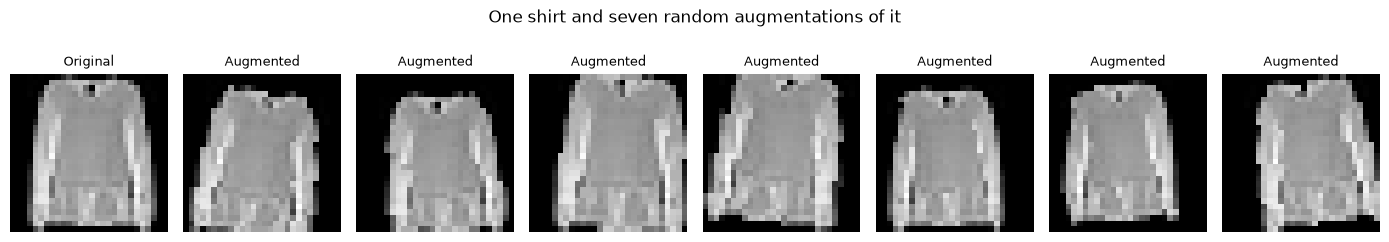

In [3]:
idx = int((raw_train.targets == 6).nonzero()[0])            # a shirt
original = Image.fromarray(raw_train.data[idx].numpy())

fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
axes[0].imshow(original, cmap="gray")
axes[0].set_title("Original", fontsize=9)
for ax in axes[1:]:
    ax.imshow(aug_pil(original), cmap="gray")                # a new random variation each time
    ax.set_title("Augmented", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle("One shirt and seven random augmentations of it", y=1.08)
plt.tight_layout()
plt.savefig("augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
xb, yb = next(iter(train_loader_aug))
print("one augmented batch:", tuple(xb.shape), tuple(yb.shape))
print("pixel range:", round(xb.min().item(), 2), "to", round(xb.max().item(), 2))
print("classes in the validation set:", torch.bincount(torch.tensor([val_set[i][1] for i in range(1000)]), minlength=10).tolist(), "(first 1000 images)")

one augmented batch: (128, 1, 28, 28) (128,)
pixel range: -0.81 to 2.02
classes in the validation set: [110, 101, 85, 86, 97, 104, 110, 92, 106, 109] (first 1000 images)


## Part 2: Three CNN Versions

All three use two convolution blocks (32 and 64 filters of size 3x3, each followed by max pooling), then a hidden layer of 128 neurons and 10 outputs.

| Version | What it adds | Training images |
|---------|--------------|-----------------|
| **A. Plain CNN** | nothing | normal |
| **B. BatchNorm + Dropout** | BatchNorm after each convolution, Dropout (30%) in the classifier | normal |
| **C. B + augmentation** | same network as B | flipped, shifted, tilted, zoomed |

Each is trained for 12 epochs with Adam (learning rate 0.001), and the epoch with the best **validation accuracy** is kept. I compare them on validation data, and the test set is only used in Part 4.

In [5]:
class FashionCNN(nn.Module):
    def __init__(self, batchnorm=False, dropout=0.0):
        super().__init__()

        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, kernel_size=3, padding=1)]
            if batchnorm:
                layers.append(nn.BatchNorm2d(cout))
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            return layers

        self.features = nn.Sequential(*block(1, 32), *block(32, 64))      # 28x28 -> 14x14 -> 7x7
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters())


print("A. plain CNN parameters:        ", f"{count_params(FashionCNN()):,}")
print("B. BatchNorm + Dropout parameters:", f"{count_params(FashionCNN(batchnorm=True, dropout=0.3)):,}")

A. plain CNN parameters:         421,642
B. BatchNorm + Dropout parameters: 421,834


In [6]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = loss_fn(out, yb)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += xb.size(0)

    return total_loss / total, correct / total


runs = {}


def train_version(name, model, loader, epochs=12, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state, t0 = 0.0, None, time.time()

    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, loader, loss_fn, optimizer)
        vl, va = run_epoch(model, val_loader, loss_fn)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        if va > best_acc:
            best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"Epoch {ep:2d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")

    seconds = time.time() - t0
    model.load_state_dict(best_state)                                   # keep the best epoch
    clean_train_acc = run_epoch(model, train_loader, loss_fn)[1]        # plain images, dropout off
    runs[name] = {"model": model, "hist": hist, "params": count_params(model), "seconds": seconds,
                  "best_epoch": int(np.argmax(hist["val_acc"])) + 1,
                  "train_acc": clean_train_acc, "val_acc": best_acc}
    print(f"\n{name}: best validation accuracy {best_acc:.4f} (epoch {runs[name]['best_epoch']}), "
          f"clean train accuracy {clean_train_acc:.4f}, time {seconds:.0f} s")


print("Training functions ready")

Training functions ready


In [7]:
torch.manual_seed(0)
train_version("A. Plain CNN", FashionCNN(), train_loader)

Epoch  1/12 | train loss 0.4709 acc 0.8308 | val loss 0.3396 acc 0.8810


Epoch  2/12 | train loss 0.2945 acc 0.8941 | val loss 0.3069 acc 0.8885


Epoch  3/12 | train loss 0.2487 acc 0.9084 | val loss 0.2538 acc 0.9053


Epoch  4/12 | train loss 0.2144 acc 0.9212 | val loss 0.2420 acc 0.9143


Epoch  5/12 | train loss 0.1912 acc 0.9302 | val loss 0.2357 acc 0.9083


...

Epoch  9/12 | train loss 0.1192 acc 0.9559 | val loss 0.2283 acc 0.9228


Epoch 10/12 | train loss 0.1026 acc 0.9621 | val loss 0.2397 acc 0.9198


Epoch 11/12 | train loss 0.0863 acc 0.9684 | val loss 0.2413 acc 0.9193


Epoch 12/12 | train loss 0.0775 acc 0.9715 | val loss 0.2546 acc 0.9235



A. Plain CNN: best validation accuracy 0.9235 (epoch 12), clean train accuracy 0.9817, time 151 s


In [8]:
torch.manual_seed(0)
train_version("B. BatchNorm + Dropout", FashionCNN(batchnorm=True, dropout=0.3), train_loader)

Epoch  1/12 | train loss 0.4609 acc 0.8312 | val loss 0.3339 acc 0.8790


Epoch  2/12 | train loss 0.3221 acc 0.8822 | val loss 0.3159 acc 0.8822


Epoch  3/12 | train loss 0.2852 acc 0.8944 | val loss 0.2539 acc 0.9015


Epoch  4/12 | train loss 0.2613 acc 0.9045 | val loss 0.2375 acc 0.9088


Epoch  5/12 | train loss 0.2412 acc 0.9107 | val loss 0.2232 acc 0.9172


...

Epoch  9/12 | train loss 0.1959 acc 0.9264 | val loss 0.2094 acc 0.9243


Epoch 10/12 | train loss 0.1819 acc 0.9321 | val loss 0.2188 acc 0.9173


Epoch 11/12 | train loss 0.1759 acc 0.9333 | val loss 0.2034 acc 0.9278


Epoch 12/12 | train loss 0.1689 acc 0.9373 | val loss 0.2038 acc 0.9257



B. BatchNorm + Dropout: best validation accuracy 0.9278 (epoch 11), clean train accuracy 0.9569, time 158 s


In [9]:
torch.manual_seed(0)
train_version("B. BatchNorm + Dropout", FashionCNN(batchnorm=True, dropout=0.3), train_loader)

Epoch  1/12 | train loss 0.4609 acc 0.8312 | val loss 0.3339 acc 0.8790


Epoch  2/12 | train loss 0.3221 acc 0.8822 | val loss 0.3159 acc 0.8822


Epoch  3/12 | train loss 0.2852 acc 0.8944 | val loss 0.2539 acc 0.9015


Epoch  4/12 | train loss 0.2613 acc 0.9045 | val loss 0.2375 acc 0.9088


Epoch  5/12 | train loss 0.2412 acc 0.9107 | val loss 0.2232 acc 0.9172


...

Epoch  9/12 | train loss 0.1959 acc 0.9264 | val loss 0.2094 acc 0.9243


Epoch 10/12 | train loss 0.1819 acc 0.9321 | val loss 0.2188 acc 0.9173


Epoch 11/12 | train loss 0.1759 acc 0.9333 | val loss 0.2034 acc 0.9278


Epoch 12/12 | train loss 0.1689 acc 0.9373 | val loss 0.2038 acc 0.9257



B. BatchNorm + Dropout: best validation accuracy 0.9278 (epoch 11), clean train accuracy 0.9569, time 752 s


In [10]:
torch.manual_seed(0)
train_version("C. B + augmentation", FashionCNN(batchnorm=True, dropout=0.3), train_loader_aug)

Epoch  1/12 | train loss 0.6947 acc 0.7397 | val loss 0.4427 acc 0.8322


Epoch  2/12 | train loss 0.5307 acc 0.8014 | val loss 0.3756 acc 0.8672


Epoch  3/12 | train loss 0.4854 acc 0.8176 | val loss 0.3419 acc 0.8723


Epoch  4/12 | train loss 0.4502 acc 0.8314 | val loss 0.3153 acc 0.8785


Epoch  5/12 | train loss 0.4343 acc 0.8394 | val loss 0.3116 acc 0.8777


...

Epoch  9/12 | train loss 0.3789 acc 0.8595 | val loss 0.2942 acc 0.8913


Epoch 10/12 | train loss 0.3694 acc 0.8639 | val loss 0.2660 acc 0.8985


Epoch 11/12 | train loss 0.3638 acc 0.8657 | val loss 0.2689 acc 0.8977


Epoch 12/12 | train loss 0.3600 acc 0.8672 | val loss 0.2537 acc 0.9067



C. B + augmentation: best validation accuracy 0.9067 (epoch 12), clean train accuracy 0.9152, time 2211 s


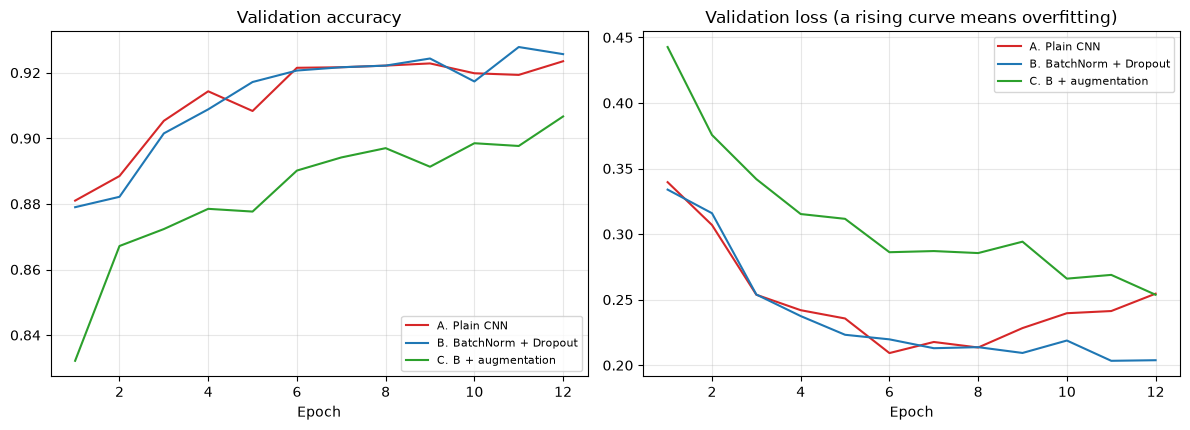

In [11]:
colors = {"A. Plain CNN": "tab:red", "B. BatchNorm + Dropout": "tab:blue", "C. B + augmentation": "tab:green"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))

for name, r in runs.items():
    ep = range(1, len(r["hist"]["val_acc"]) + 1)
    ax[0].plot(ep, r["hist"]["val_acc"], color=colors[name], label=name)
    ax[1].plot(ep, r["hist"]["val_loss"], color=colors[name], label=name)

ax[0].set_title("Validation accuracy")
ax[1].set_title("Validation loss (a rising curve means overfitting)")
for a in ax:
    a.set_xlabel("Epoch")
    a.grid(alpha=0.3)
    a.legend(fontsize=8)

plt.tight_layout()
plt.savefig("version_curves.png", dpi=150)
plt.show()

In [12]:
print(f"{'version':<26}{'params':>9}{'time (s)':>10}{'best ep':>9}{'train':>8}{'val':>8}{'gap':>8}")
for name, r in runs.items():
    print(f"{name:<26}{r['params']:>9,}{r['seconds']:>10.0f}{r['best_epoch']:>9}"
          f"{r['train_acc']:>8.4f}{r['val_acc']:>8.4f}{r['train_acc'] - r['val_acc']:>8.4f}")

best_name = max(runs, key=lambda n: runs[n]["val_acc"])
print("\nBest on validation data:", best_name, f"({runs[best_name]['val_acc']:.4f})")

version                      params  time (s)  best ep   train     val     gap
A. Plain CNN                421,642       151       12  0.9817  0.9235  0.0582
B. BatchNorm + Dropout      421,834       752       11  0.9569  0.9278  0.0291
C. B + augmentation         421,834      2211       12  0.9152  0.9067  0.0085

Best on validation data: B. BatchNorm + Dropout (0.9278)


In [13]:
from IPython.display import Markdown, display

A, B, C = (runs[n] for n in runs)
bn_gain = (B["val_acc"] - A["val_acc"]) * 100
aug_gain = (C["val_acc"] - B["val_acc"]) * 100
gap = lambda r: (r["train_acc"] - r["val_acc"]) * 100

aug_text = (f"Training on augmented images changed validation accuracy by **{aug_gain:+.2f} points** compared with B"
            + (" and reduced the train-validation gap, so it helped generalization."
               if gap(C) < gap(B) else ", and the gap did not shrink."))

text = f"""
### What the three versions show (numbers computed from my own results)

- **Best version on validation data:** **{best_name}** with **{runs[best_name]['val_acc'] * 100:.2f}%** validation accuracy.
- **Plain CNN (A):** {A['val_acc'] * 100:.2f}% on validation but **{A['train_acc'] * 100:.2f}%** on the training images, a gap of **{gap(A):.1f} points**. It fits the training set much better than new images, which is overfitting.
- **BatchNorm + Dropout (B):** validation accuracy changed by **{bn_gain:+.2f} points** compared with A, and the gap went from {gap(A):.1f} to **{gap(B):.1f} points**.
- **Augmentation (C):** {aug_text} Its gap is **{gap(C):.1f} points**.
- **Cost:** all three have almost the same size ({A['params']:,} to {B['params']:,} parameters). Training time was {A['seconds']:.0f} s for A, {B['seconds']:.0f} s for B and {C['seconds']:.0f} s for C, since augmentation makes every epoch a little slower.
"""
display(Markdown(text))


### What the three versions show (numbers computed from my own results)

- **Best version on validation data:** **B. BatchNorm + Dropout** with **92.78%** validation accuracy.
- **Plain CNN (A):** 92.35% on validation but **98.17%** on the training images, a gap of **5.8 points**. It fits the training set much better than new images, which is overfitting.
- **BatchNorm + Dropout (B):** validation accuracy changed by **+0.43 points** compared with A, and the gap went from 5.8 to **2.9 points**.
- **Augmentation (C):** Training on augmented images changed validation accuracy by **-2.12 points** compared with B and reduced the train-validation gap, so it helped generalization. Its gap is **0.9 points**.
- **Cost:** all three have almost the same size (421,642 to 421,834 parameters). Training time was 151 s for A, 752 s for B and 2211 s for C, since augmentation makes every epoch a little slower.


## Part 4: Test Results

The test set (10,000 images) was not used for training or for choosing the best version. I evaluate all three versions on it and show the final **comparison table**. The **best version was chosen on validation data**, before looking at the test scores. For the chosen model I report **precision, recall and F1 for each class**, the **confusion matrix** and the **accuracy for each clothing class**.

In [14]:
import csv


@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    probs, labels, images = [], [], []
    for xb, yb in loader:
        out = model(xb.to(device))
        probs.append(torch.softmax(out, dim=1).cpu())
        labels.append(yb)
        images.append(xb)
    return torch.cat(probs), torch.cat(labels), torch.cat(images)


test_results = {}
for name, r in runs.items():
    probs, test_labels, test_images = predict_all(r["model"], test_loader)
    pred = probs.argmax(1)
    test_results[name] = {"probs": probs, "pred": pred}
    r["test_acc"] = (pred == test_labels).float().mean().item()

print(f"{'version':<26}{'params':>9}{'time (s)':>10}{'train':>8}{'val':>8}{'test':>8}{'gap':>8}")
for name, r in runs.items():
    print(f"{name:<26}{r['params']:>9,}{r['seconds']:>10.0f}{r['train_acc']:>8.4f}{r['val_acc']:>8.4f}"
          f"{r['test_acc']:>8.4f}{r['train_acc'] - r['val_acc']:>8.4f}")

print("\nChosen on validation data:", best_name)
print(f"Its test accuracy: {runs[best_name]['test_acc'] * 100:.2f}%  "
      f"(wrong on {int((test_results[best_name]['pred'] != test_labels).sum())} of 10,000 images)")

with open("comparison_table.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["version", "params", "train_seconds", "best_epoch", "train_acc", "val_acc", "test_acc"])
    for name, r in runs.items():
        w.writerow([name, r["params"], round(r["seconds"]), r["best_epoch"],
                    round(r["train_acc"], 4), round(r["val_acc"], 4), round(r["test_acc"], 4)])
print("Saved comparison_table.csv")

version                      params  time (s)   train     val    test     gap
A. Plain CNN                421,642       151  0.9817  0.9235  0.9197  0.0582
B. BatchNorm + Dropout      421,834       752  0.9569  0.9278  0.9209  0.0291
C. B + augmentation         421,834      2211  0.9152  0.9067  0.9028  0.0085

Chosen on validation data: B. BatchNorm + Dropout
Its test accuracy: 92.09%  (wrong on 791 of 10,000 images)
Saved comparison_table.csv


In [15]:
from sklearn.metrics import classification_report

chosen_probs = test_results[best_name]["probs"]
chosen_pred = test_results[best_name]["pred"]

print(f"Classification report for {best_name}\n")
print(classification_report(test_labels, chosen_pred, target_names=CLASSES, digits=3))

Classification report for B. BatchNorm + Dropout

              precision    recall  f1-score   support

 T-shirt/top      0.863     0.894     0.878      1000
     Trouser      0.994     0.986     0.990      1000
    Pullover      0.888     0.858     0.873      1000
       Dress      0.922     0.923     0.923      1000
        Coat      0.906     0.851     0.878      1000
      Sandal      0.991     0.978     0.984      1000
       Shirt      0.739     0.792     0.764      1000
     Sneaker      0.959     0.976     0.967      1000
         Bag      0.991     0.982     0.986      1000
  Ankle boot      0.971     0.969     0.970      1000

    accuracy                          0.921     10000
   macro avg      0.922     0.921     0.921     10000
weighted avg      0.922     0.921     0.921     10000



In [16]:
from sklearn.metrics import classification_report

chosen_probs = test_results[best_name]["probs"]
chosen_pred = test_results[best_name]["pred"]

print(f"Classification report for {best_name}\n")
print(classification_report(test_labels, chosen_pred, target_names=CLASSES, digits=3))

Classification report for B. BatchNorm + Dropout

              precision    recall  f1-score   support

 T-shirt/top      0.863     0.894     0.878      1000
     Trouser      0.994     0.986     0.990      1000
    Pullover      0.888     0.858     0.873      1000
       Dress      0.922     0.923     0.923      1000
        Coat      0.906     0.851     0.878      1000
      Sandal      0.991     0.978     0.984      1000
       Shirt      0.739     0.792     0.764      1000
     Sneaker      0.959     0.976     0.967      1000
         Bag      0.991     0.982     0.986      1000
  Ankle boot      0.971     0.969     0.970      1000

    accuracy                          0.921     10000
   macro avg      0.922     0.921     0.921     10000
weighted avg      0.922     0.921     0.921     10000



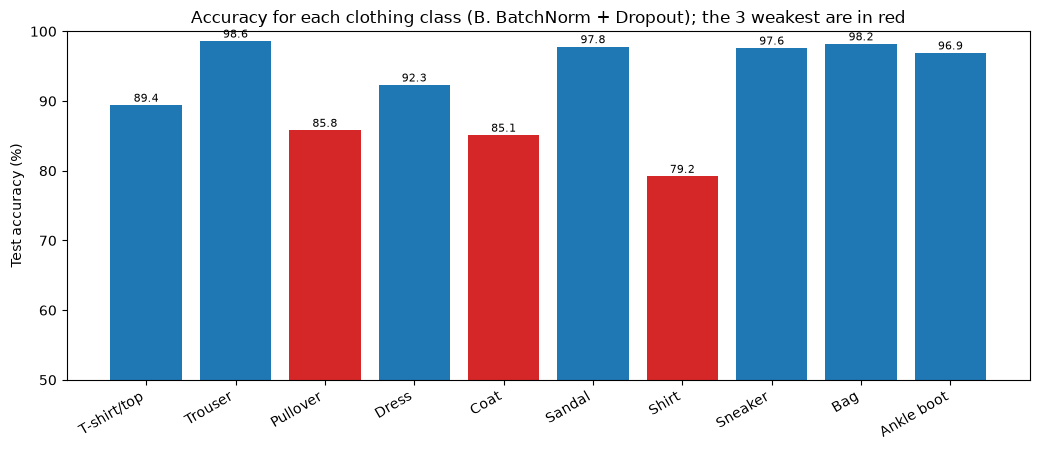

Weakest classes: Shirt (79.2%), Coat (85.1%), Pullover (85.8%)
Strongest classes: Trouser (98.6%), Bag (98.2%), Sandal (97.8%)


In [17]:
per_class = np.array([(chosen_pred[test_labels == c] == c).float().mean().item() for c in range(10)])
order = np.argsort(per_class)

plt.figure(figsize=(10.5, 4.6))
bars = plt.bar(range(10), per_class * 100, color=["tab:red" if k in order[:3] else "tab:blue" for k in range(10)])
plt.xticks(range(10), CLASSES, rotation=30, ha="right")
plt.ylim(50, 100)
plt.ylabel("Test accuracy (%)")
plt.title(f"Accuracy for each clothing class ({best_name}); the 3 weakest are in red")
for b, v in zip(bars, per_class):
    plt.text(b.get_x() + b.get_width() / 2, v * 100 + 0.5, f"{v * 100:.1f}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("per_class_accuracy.png", dpi=150)
plt.show()

print("Weakest classes:", ", ".join(f"{CLASSES[c]} ({per_class[c] * 100:.1f}%)" for c in order[:3]))
print("Strongest classes:", ", ".join(f"{CLASSES[c]} ({per_class[c] * 100:.1f}%)" for c in order[::-1][:3]))

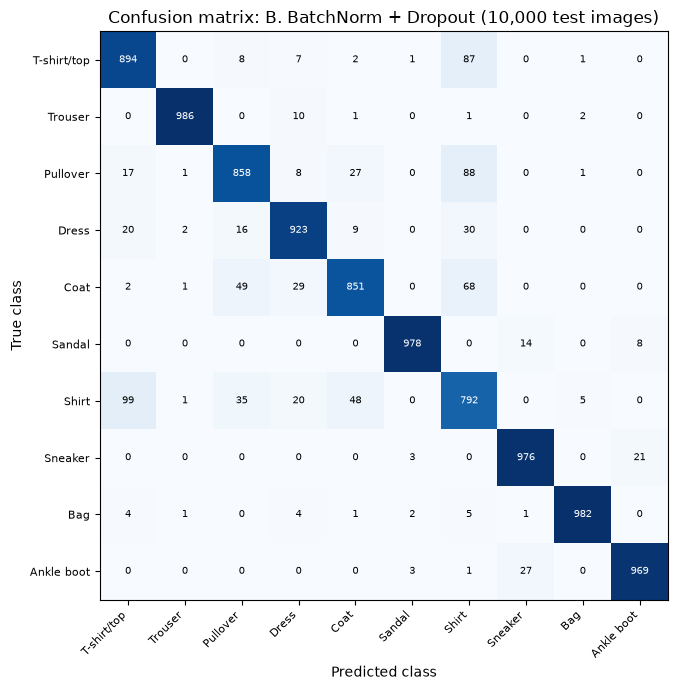

Most common mistakes (true class -> predicted class):
  Shirt        -> T-shirt/top    99 times
  Pullover     -> Shirt          88 times
  T-shirt/top  -> Shirt          87 times
  Coat         -> Shirt          68 times
  Coat         -> Pullover       49 times
  Shirt        -> Coat           48 times


In [18]:
cm = torch.bincount(test_labels * 10 + chosen_pred, minlength=100).reshape(10, 10)

fig, ax = plt.subplots(figsize=(8.5, 7))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(10), CLASSES, fontsize=8)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"Confusion matrix: {best_name} (10,000 test images)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() * 0.5 else "black")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

top_pairs = sorted([(int(cm[t, p]), t, p) for t in range(10) for p in range(10) if t != p], reverse=True)
print("Most common mistakes (true class -> predicted class):")
for count, t, p in top_pairs[:6]:
    print(f"  {CLASSES[t]:<12} -> {CLASSES[p]:<12} {count:>4} times")

In [19]:
from IPython.display import Markdown, display

rb = runs[best_name]
weak = ", ".join(CLASSES[c] for c in order[:3])
strong = ", ".join(CLASSES[c] for c in order[::-1][:3])
pairs_text = ", ".join(f"{CLASSES[t]} read as {CLASSES[p]} ({count} times)" for count, t, p in top_pairs[:3])
n_wrong = int((chosen_pred != test_labels).sum())
conf_ok = chosen_probs.max(1).values[chosen_pred == test_labels].mean().item()
conf_bad = chosen_probs.max(1).values[chosen_pred != test_labels].mean().item()
test_rows = "\n".join(f"| {n} | {r['val_acc'] * 100:.2f}% | {r['test_acc'] * 100:.2f}% |" for n, r in runs.items())

text = f"""
### What the test results show (numbers computed from my own results)

| Version | Validation accuracy | Test accuracy |
|---------|--------------------|---------------|
{test_rows}

- **Chosen model:** **{best_name}**, selected on validation data. Its test accuracy is **{rb['test_acc'] * 100:.2f}%** ({n_wrong} wrong out of 10,000).
- **It generalizes:** validation accuracy ({rb['val_acc'] * 100:.2f}%) and test accuracy ({rb['test_acc'] * 100:.2f}%) differ by only **{abs(rb['val_acc'] - rb['test_acc']) * 100:.2f} points**, so choosing on validation data held up on unseen images.
- **Easy classes:** {strong}. These items have a distinctive shape.
- **Hard classes:** {weak}. These garments have similar outlines, so they are confused with each other. The most frequent confusions are {pairs_text}.
- **Confidence:** the model's average confidence is **{conf_ok:.2f}** on correct predictions and **{conf_bad:.2f}** on wrong ones, so low confidence is a useful warning sign.
"""
display(Markdown(text))


### What the test results show (numbers computed from my own results)

| Version | Validation accuracy | Test accuracy |
|---------|--------------------|---------------|
| A. Plain CNN | 92.35% | 91.97% |
| B. BatchNorm + Dropout | 92.78% | 92.09% |
| C. B + augmentation | 90.67% | 90.28% |

- **Chosen model:** **B. BatchNorm + Dropout**, selected on validation data. Its test accuracy is **92.09%** (791 wrong out of 10,000).
- **It generalizes:** validation accuracy (92.78%) and test accuracy (92.09%) differ by only **0.69 points**, so choosing on validation data held up on unseen images.
- **Easy classes:** Trouser, Bag, Sandal. These items have a distinctive shape.
- **Hard classes:** Shirt, Coat, Pullover. These garments have similar outlines, so they are confused with each other. The most frequent confusions are Shirt read as T-shirt/top (99 times), Pullover read as Shirt (88 times), T-shirt/top read as Shirt (87 times).
- **Confidence:** the model's average confidence is **0.95** on correct predictions and **0.69** on wrong ones, so low confidence is a useful warning sign.


## Part 5: Prediction Gallery

Pictures of the chosen model's predictions on **test images it has never seen**. Titles show the predicted class and the model's confidence. **Green = correct, red = wrong.**

1. a **random sample** (fixed seed, so no cherry-picking)
2. **six examples of every clothing class**
3. the model's **most confident mistakes**

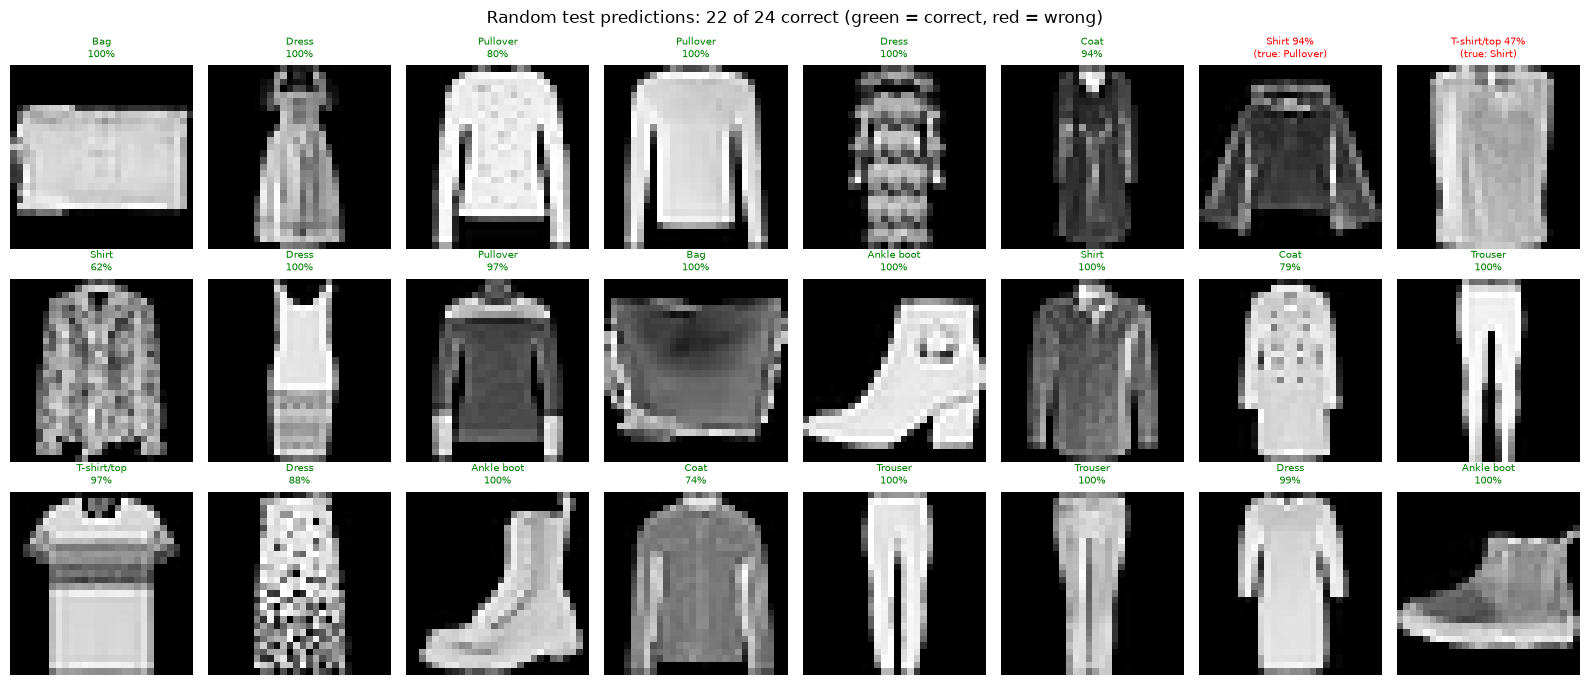

In [20]:
def show_img(ax, i, with_true=True):
    pred, true = int(chosen_pred[i]), int(test_labels[i])
    conf = chosen_probs[i, pred].item() * 100
    ax.imshow(test_images[i].squeeze() * STD + MEAN, cmap="gray")
    ok = pred == true
    label = CLASSES[pred] if with_true else f"{CLASSES[pred]}"
    title = f"{label}\n{conf:.0f}%" if ok else f"{CLASSES[pred]} {conf:.0f}%\n(true: {CLASSES[true]})"
    ax.set_title(title, fontsize=7.5, color="green" if ok else "red")
    ax.axis("off")


rng = np.random.default_rng(11)
sample_idx = rng.choice(len(test_labels), 24, replace=False)

fig, axes = plt.subplots(3, 8, figsize=(16, 7))
for ax, i in zip(axes.flat, sample_idx):
    show_img(ax, int(i))
n_ok = int((chosen_pred[sample_idx] == test_labels[sample_idx]).sum())
plt.suptitle(f"Random test predictions: {n_ok} of 24 correct (green = correct, red = wrong)", fontsize=12)
plt.tight_layout()
plt.savefig("prediction_gallery.png", dpi=150)
plt.show()

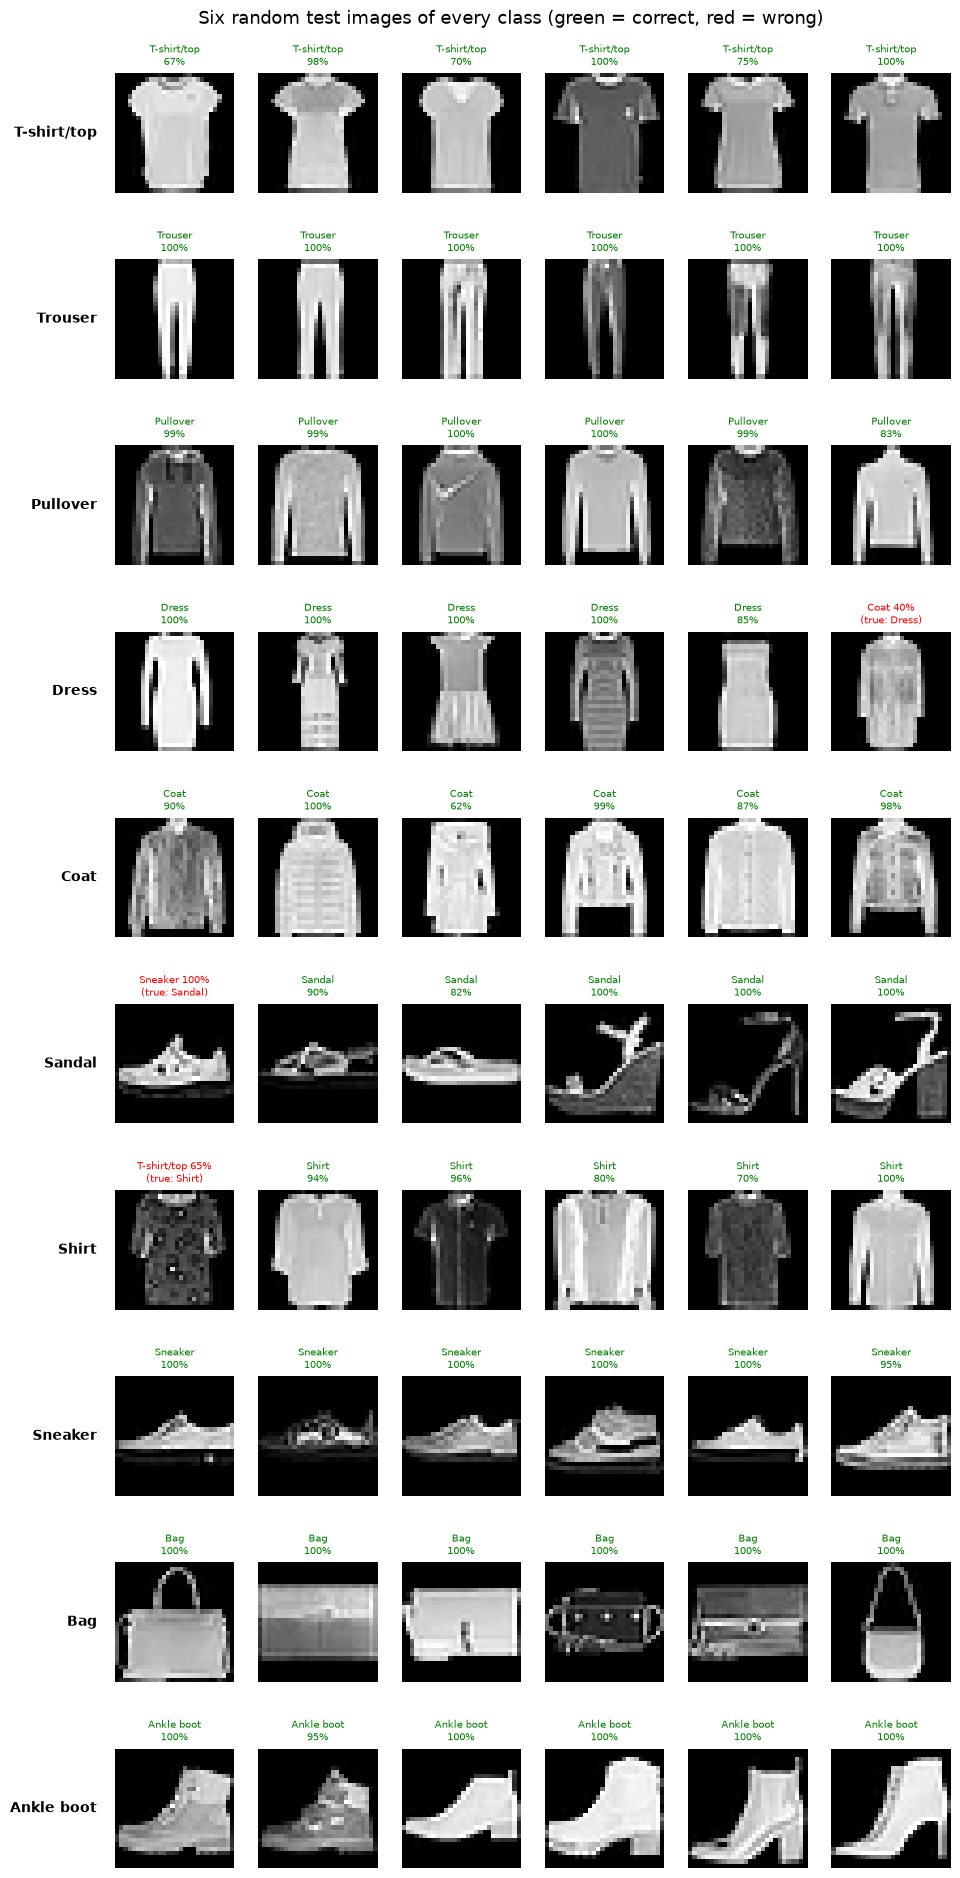

In [21]:
rng = np.random.default_rng(5)
fig, axes = plt.subplots(10, 6, figsize=(11, 21))

for c in range(10):
    pool = (test_labels == c).nonzero().flatten().numpy()
    pick = rng.choice(pool, 6, replace=False)
    for col, i in enumerate(pick):
        show_img(axes[c, col], int(i))
    axes[c, 0].text(-0.15, 0.5, CLASSES[c], transform=axes[c, 0].transAxes,
                    ha="right", va="center", fontsize=10, fontweight="bold")

plt.suptitle("Six random test images of every class (green = correct, red = wrong)", fontsize=13, y=0.995)
plt.subplots_adjust(left=0.14, top=0.965, hspace=0.55)
plt.savefig("class_gallery.png", dpi=130, bbox_inches="tight")
plt.show()

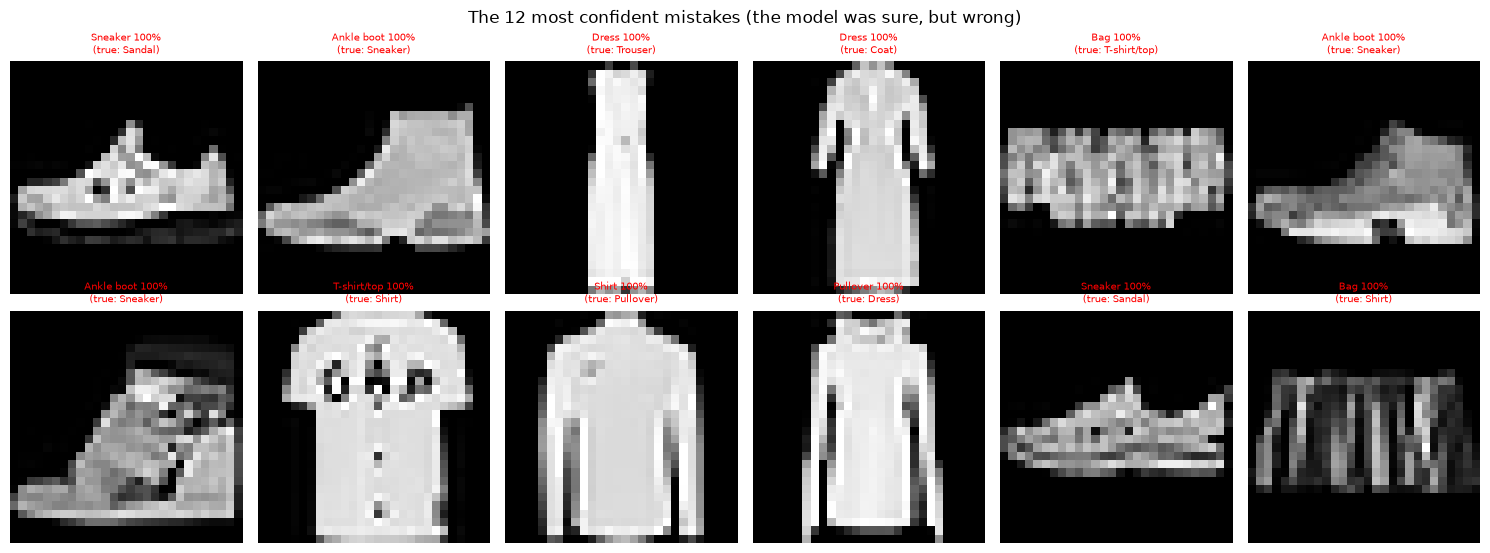

In [22]:
wrong_idx = (chosen_pred != test_labels).nonzero().flatten()
wrong_conf = chosen_probs[wrong_idx, chosen_pred[wrong_idx]]
top_wrong = wrong_idx[wrong_conf.argsort(descending=True)][:12].tolist()

fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))
for ax, i in zip(axes.flat, top_wrong):
    show_img(ax, i)
plt.suptitle("The 12 most confident mistakes (the model was sure, but wrong)", fontsize=12)
plt.tight_layout()
plt.savefig("wrong_predictions.png", dpi=150)
plt.show()

In [23]:
from IPython.display import Markdown, display

conf_all = chosen_probs.max(1).values
correct = chosen_pred == test_labels

rows = []
for lo, hi, name in [(0.0, 0.7, "below 70%"), (0.7, 0.9, "70% to 90%"), (0.9, 0.99, "90% to 99%"), (0.99, 1.01, "99% or more")]:
    m = (conf_all >= lo) & (conf_all < hi)
    if m.any():
        rows.append(f"| {name} | {int(m.sum()):,} | {correct[m].float().mean().item() * 100:.1f}% |")

sure_wrong = int(((conf_all > 0.9) & ~correct).sum())
text = f"""
### What the galleries show (numbers computed from my own results)

| Model confidence | Number of test images | Accuracy |
|------------------|----------------------|----------|
{chr(10).join(rows)}

- In the random sample, **{n_ok} of 24** predictions were correct, close to the overall test accuracy of **{runs[best_name]['test_acc'] * 100:.1f}%**.
- The higher the confidence, the more accurate the predictions, so confidence is a **useful warning sign**.
- But **{sure_wrong} images** were classified wrongly with more than 90% confidence, so a high probability does not guarantee a correct answer.
- The confident mistakes mostly involve garments with similar shapes (tops, pullovers, shirts and coats) or images where details such as sleeves or collars are hard to see at 28x28.
"""
display(Markdown(text))


### What the galleries show (numbers computed from my own results)

| Model confidence | Number of test images | Accuracy |
|------------------|----------------------|----------|
| below 70% | 968 | 56.1% |
| 70% to 90% | 1,090 | 78.2% |
| 90% to 99% | 1,698 | 93.6% |
| 99% or more | 6,244 | 99.7% |

- In the random sample, **22 of 24** predictions were correct, close to the overall test accuracy of **92.1%**.
- The higher the confidence, the more accurate the predictions, so confidence is a **useful warning sign**.
- But **128 images** were classified wrongly with more than 90% confidence, so a high probability does not guarantee a correct answer.
- The confident mistakes mostly involve garments with similar shapes (tops, pullovers, shirts and coats) or images where details such as sleeves or collars are hard to see at 28x28.


## Part 6: Saved Model

I save the chosen model in a single file, `fashion_cnn.pth`. It contains the **learned weights**, the **settings needed to rebuild the network**, the **class names**, the **normalization values** and the **test accuracy**. Then I **reload it into a fresh network** and check that it gives exactly the same predictions as before.

In [24]:
configs = {"A. Plain CNN": dict(batchnorm=False, dropout=0.0),
           "B. BatchNorm + Dropout": dict(batchnorm=True, dropout=0.3),
           "C. B + augmentation": dict(batchnorm=True, dropout=0.3)}

best_model = runs[best_name]["model"]
checkpoint = {
    "model_state": {k: v.cpu() for k, v in best_model.state_dict().items()},
    "model_name": best_name,
    "model_config": configs[best_name],
    "classes": CLASSES,
    "mean": MEAN,
    "std": STD,
    "val_accuracy": runs[best_name]["val_acc"],
    "test_accuracy": runs[best_name]["test_acc"],
}
torch.save(checkpoint, "fashion_cnn.pth")

print("Saved in folder:", os.getcwd())
print("File size:", round(os.path.getsize("fashion_cnn.pth") / 1024), "KB")
print("The file contains:", list(checkpoint.keys()))

Saved in folder: /Users/bhoomikamt/Documents/Deep-Learning-AI-Internship/Week-03/Mini-Project
File size: 1655 KB
The file contains: ['model_state', 'model_name', 'model_config', 'classes', 'mean', 'std', 'val_accuracy', 'test_accuracy']


In [25]:
loaded = torch.load("fashion_cnn.pth", map_location="cpu")

reloaded = FashionCNN(**loaded["model_config"])        # a brand-new network with the same design
reloaded.load_state_dict(loaded["model_state"])        # fill it with the saved weights
reloaded = reloaded.to(device).eval()

probs2, labels2, _ = predict_all(reloaded, test_loader)
same_pred = bool((probs2.argmax(1) == chosen_pred).all())
max_diff = (probs2 - chosen_probs).abs().max().item()
acc2 = (probs2.argmax(1) == labels2).float().mean().item()

print("Loaded model:", loaded["model_name"])
print(f"Test accuracy of the reloaded model: {acc2 * 100:.2f}%  (saved value: {loaded['test_accuracy'] * 100:.2f}%)")
print("Same prediction as before for all 10,000 images:", same_pred)
print("Largest difference in any probability:", f"{max_diff:.2e}")

Loaded model: B. BatchNorm + Dropout
Test accuracy of the reloaded model: 92.09%  (saved value: 92.09%)
Same prediction as before for all 10,000 images: True
Largest difference in any probability: 0.00e+00


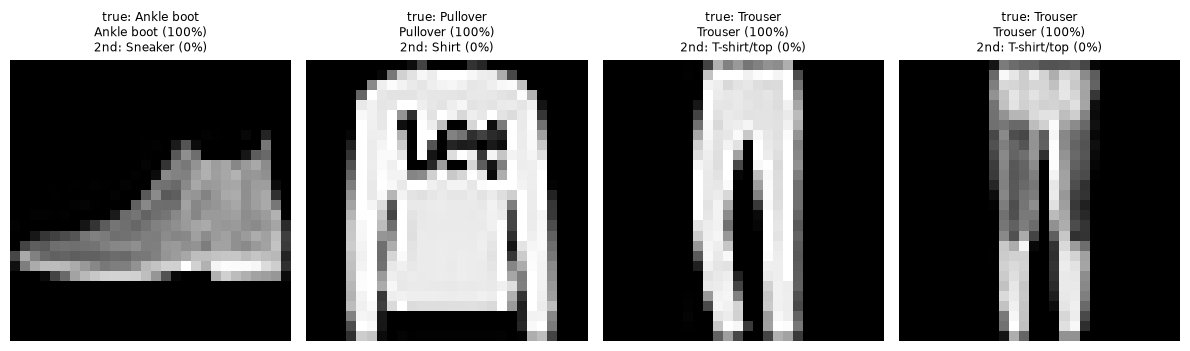

In [26]:
def prepare_image(img):
    """PIL image -> (1,1,28,28) tensor in Fashion-MNIST format (light item on a dark background)."""
    g = img.convert("L")
    a = np.array(g)
    edge = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
    bg = int(np.median(edge))                                  # background brightness from the border
    w, h = g.size
    side = max(w, h)
    canvas = Image.new("L", (side, side), bg)                  # pad to a square, so the item is not stretched
    canvas.paste(g, ((side - w) // 2, (side - h) // 2))
    arr = np.array(canvas.resize((28, 28), Image.LANCZOS), dtype=np.float32) / 255.0
    if bg > 127:                                               # light background -> invert, like the dataset
        arr = 1.0 - arr
    x = (torch.from_numpy(arr) - loaded["mean"]) / loaded["std"]
    return x[None, None], arr


@torch.no_grad()
def predict_image(img, model=reloaded, top=3):
    x, arr = prepare_image(img)
    p = torch.softmax(model(x.to(device)), dim=1)[0].cpu()
    best = p.topk(top)
    return [(loaded["classes"][int(i)], float(v)) for v, i in zip(best.values, best.indices)], arr


# demo: send 4 raw test images through the complete pipeline
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, i in zip(axes, [0, 1, 2, 3]):
    pic = Image.fromarray(test_set.data[i].numpy())
    guesses, arr = predict_image(pic)
    ax.imshow(arr, cmap="gray")
    ax.set_title(f"true: {CLASSES[int(test_set.targets[i])]}\n"
                 f"{guesses[0][0]} ({guesses[0][1] * 100:.0f}%)\n2nd: {guesses[1][0]} ({guesses[1][1] * 100:.0f}%)",
                 fontsize=8.5)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [27]:
my_picture = ""        # example: "my_item.jpg"  (put the file in this same folder, then run the cell again)

if my_picture and os.path.exists(my_picture):
    pic = Image.open(my_picture)
    guesses, arr = predict_image(pic)
    fig, ax = plt.subplots(1, 2, figsize=(7, 3.2))
    ax[0].imshow(pic)
    ax[0].set_title("my picture")
    ax[1].imshow(arr, cmap="gray")
    ax[1].set_title("what the model sees (28x28)")
    for a in ax:
        a.axis("off")
    plt.show()
    for name, p in guesses:
        print(f"{name:<14}{p * 100:5.1f}%")
else:
    print("No picture chosen. This cell is optional.")

No picture chosen. This cell is optional.


### How to use the saved model

    checkpoint = torch.load("fashion_cnn.pth", map_location="cpu")
    model = FashionCNN(**checkpoint["model_config"])
    model.load_state_dict(checkpoint["model_state"])
    model.eval()

The checkpoint also stores the **class names** and the **normalization values (mean and std)**, so anyone loading the file prepares images the same way as in training. The model was trained on small 28x28 grayscale pictures of single garments, so photos with a busy background or unusual angles can be classified less reliably.

## Part 7: Extra, What Does the Model Look At?

An **occlusion map** shows which parts of an image the model relies on. I slide a small gray square (6x6 pixels) over the image. At each position I cover that part and measure how much the model's confidence in its answer **drops**. A big drop means the covered region was important. **Red = regions the model relies on.**

In [28]:
@torch.no_grad()
def occlusion_map(model, x, target, patch=6, stride=2):
    model.eval()
    base = torch.softmax(model(x.to(device)), dim=1)[0, target].item()
    starts = list(range(0, 28 - patch + 1, stride))
    batch, coords = [], []
    for r in starts:
        for c in starts:
            xo = x.clone()
            xo[:, :, r:r + patch, c:c + patch] = 0.0          # cover this square with gray
            batch.append(xo)
            coords.append((r, c))
    probs = torch.softmax(model(torch.cat(batch).to(device)), dim=1)[:, target].cpu()
    heat, count = torch.zeros(28, 28), torch.zeros(28, 28)
    for (r, c), p in zip(coords, probs):
        heat[r:r + patch, c:c + patch] += base - p.item()     # how much the confidence dropped
        count[r:r + patch, c:c + patch] += 1
    return (heat / count.clamp(min=1)).clamp(min=0), base


def explain(i, target):
    heat, base = occlusion_map(reloaded, test_images[i:i + 1], target)
    raw = test_images[i].squeeze() * STD + MEAN
    item = raw > 0.2                                           # pixels that belong to the garment
    inside = (heat[item].sum() / heat.sum().clamp(min=1e-9)).item()
    return heat, base, raw, inside, item.float().mean().item()


is_right = chosen_pred == test_labels
good = [int(((test_labels == c) & is_right).nonzero().flatten()[0]) for c in [1, 2, 5, 6, 8, 9]]
bad = top_wrong[:6]                                            # the confident mistakes from Part 5

good_results = [explain(i, int(chosen_pred[i])) for i in good]
bad_results = [explain(i, int(chosen_pred[i])) for i in bad]
print("occlusion maps computed for", len(good_results) + len(bad_results), "images")

occlusion maps computed for 12 images


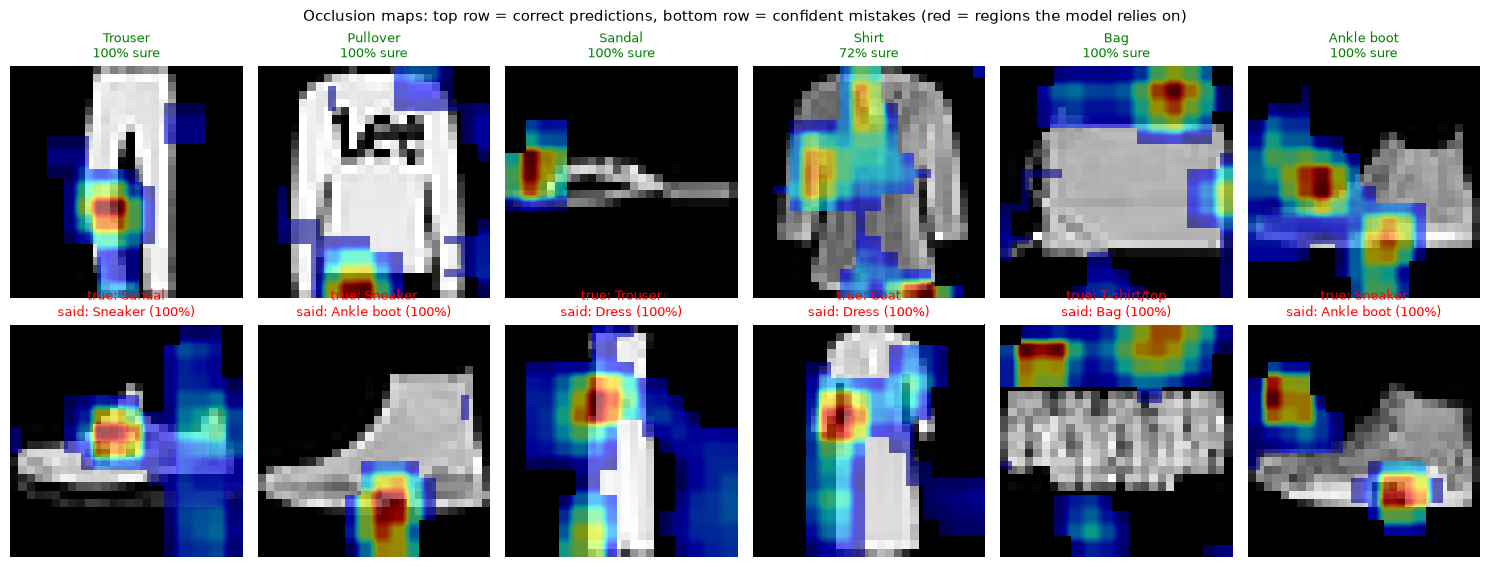

In [29]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.8))
for row, (idxs, results, is_correct) in enumerate([(good, good_results, True), (bad, bad_results, False)]):
    for col, (i, res) in enumerate(zip(idxs, results)):
        heat, base, raw, inside, share = res
        ax = axes[row, col]
        ax.imshow(raw, cmap="gray", vmin=0, vmax=1)
        ax.imshow(np.ma.masked_less(heat.numpy(), 0.1 * max(heat.max().item(), 1e-9)),
                  cmap="jet", alpha=0.6, interpolation="bilinear")
        pred, true = int(chosen_pred[i]), int(test_labels[i])
        if is_correct:
            ax.set_title(f"{CLASSES[pred]}\n{base * 100:.0f}% sure", fontsize=9, color="green")
        else:
            ax.set_title(f"true: {CLASSES[true]}\nsaid: {CLASSES[pred]} ({base * 100:.0f}%)", fontsize=9, color="red")
        ax.axis("off")

plt.suptitle("Occlusion maps: top row = correct predictions, bottom row = confident mistakes (red = regions the model relies on)",
             fontsize=11)
plt.tight_layout()
plt.savefig("occlusion_map.png", dpi=150)
plt.show()

In [30]:
from IPython.display import Markdown, display

inside_good = float(np.mean([r[3] for r in good_results])) * 100
area_good = float(np.mean([r[4] for r in good_results])) * 100
inside_bad = float(np.mean([r[3] for r in bad_results])) * 100
focus = ("so it looks at the garment itself and not at the empty background"
         if inside_good > area_good + 10 else "so it does not clearly concentrate on the garment")

text = f"""
### What the occlusion maps show (numbers computed from my own results)

- On the correct predictions, **{inside_good:.0f}%** of the importance falls on pixels that belong to the garment, which covers only **{area_good:.0f}%** of the image, {focus}.
- For the confident mistakes, **{inside_bad:.0f}%** of the importance is on the garment. A model can look at the right object and still decide wrongly, because the garment's shape resembles another class.
- The bottom row shows which parts of the garment pushed the model towards the wrong class. Compare these regions with the true class to see which details (sleeves, collar, length) caused the confusion.
"""
display(Markdown(text))


### What the occlusion maps show (numbers computed from my own results)

- On the correct predictions, **44%** of the importance falls on pixels that belong to the garment, which covers only **39%** of the image, so it does not clearly concentrate on the garment.
- For the confident mistakes, **36%** of the importance is on the garment. A model can look at the right object and still decide wrongly, because the garment's shape resembles another class.
- The bottom row shows which parts of the garment pushed the model towards the wrong class. Compare these regions with the true class to see which details (sleeves, collar, length) caused the confusion.


In [31]:
A, B, C = (runs[n] for n in runs)

conclusion = f"""
## Part 8: Conclusion

- **Result:** a CNN trained on Fashion-MNIST recognizes the 10 clothing categories with **{rb['test_acc'] * 100:.2f}%** accuracy on 10,000 test images that were never used for training or for choosing the model ({n_wrong} mistakes).
- **Comparing three versions:** the plain CNN reached {A['val_acc'] * 100:.2f}% validation accuracy, adding BatchNorm and Dropout gave {B['val_acc'] * 100:.2f}%, and training on augmented images gave {C['val_acc'] * 100:.2f}%. I chose **{best_name}** on validation data.
- **Where it fails:** the weakest classes are {weak}, and the most frequent confusions are {pairs_text}. These garments have similar outlines, and at 28x28 pixels their distinguishing details are only a pixel or two wide.
- **Confidence:** the average confidence is {conf_ok:.2f} for correct predictions and {conf_bad:.2f} for wrong ones, but {sure_wrong} wrong predictions were made with more than 90% confidence, so confidence is a hint and not a guarantee.
- **What the model looks at:** occlusion maps show that {inside_good:.0f}% of the importance falls on the garment itself.
- **Saved model:** `fashion_cnn.pth` holds the weights, the network settings, the class names and the normalization values. I reloaded it into a fresh network and it gave identical predictions on all 10,000 test images: **{same_pred}**.
"""
display(Markdown(conclusion))


## Part 8: Conclusion

- **Result:** a CNN trained on Fashion-MNIST recognizes the 10 clothing categories with **92.09%** accuracy on 10,000 test images that were never used for training or for choosing the model (791 mistakes).
- **Comparing three versions:** the plain CNN reached 92.35% validation accuracy, adding BatchNorm and Dropout gave 92.78%, and training on augmented images gave 90.67%. I chose **B. BatchNorm + Dropout** on validation data.
- **Where it fails:** the weakest classes are Shirt, Coat, Pullover, and the most frequent confusions are Shirt read as T-shirt/top (99 times), Pullover read as Shirt (88 times), T-shirt/top read as Shirt (87 times). These garments have similar outlines, and at 28x28 pixels their distinguishing details are only a pixel or two wide.
- **Confidence:** the average confidence is 0.95 for correct predictions and 0.69 for wrong ones, but 128 wrong predictions were made with more than 90% confidence, so confidence is a hint and not a guarantee.
- **What the model looks at:** occlusion maps show that 44% of the importance falls on the garment itself.
- **Saved model:** `fashion_cnn.pth` holds the weights, the network settings, the class names and the normalization values. I reloaded it into a fresh network and it gave identical predictions on all 10,000 test images: **True**.


In [32]:
rows = "\n".join(
    f"| {n} | {r['params']:,} | {r['train_acc'] * 100:.2f}% | {r['val_acc'] * 100:.2f}% | {r['test_acc'] * 100:.2f}% | {(r['train_acc'] - r['val_acc']) * 100:.1f} |"
    for n, r in runs.items())
weak_text = ", ".join(f"{CLASSES[c]} ({per_class[c] * 100:.1f}%)" for c in order[:3])
strong_text = ", ".join(f"{CLASSES[c]} ({per_class[c] * 100:.1f}%)" for c in order[::-1][:3])

readme = f"""# Fashion Item Recognition: CNNs on Fashion-MNIST

Week 3 mini project of the Deep Learning & AI Internship (NEXIS Solutions).

A convolutional neural network classifies clothing images into 10 categories (T-shirt/top, trouser, pullover, dress, coat, sandal, shirt, sneaker, bag, ankle boot). Three CNN versions are compared, the best one is chosen on validation data and saved, and its mistakes and attention are studied.

## Results

| Metric | Value |
|--------|-------|
| **Chosen model** | {best_name} |
| **Test accuracy** | **{rb['test_acc'] * 100:.2f}%** |
| Validation accuracy | {rb['val_acc'] * 100:.2f}% |
| Wrong test predictions | {n_wrong} of 10,000 |
| Saved model | `fashion_cnn.pth` (reload gives identical predictions: {same_pred}) |

## Required output

| Requirement | Where |
|-------------|-------|
| Working notebook | `fashion_recognizer.ipynb` |
| Comparison table | below and `comparison_table.csv` |
| Prediction gallery | below |
| Saved model | `fashion_cnn.pth` |

## Comparison table

| Version | Parameters | Train acc | Validation acc | Test acc | Gap (points) |
|---------|-----------|-----------|----------------|----------|--------------|
{rows}

![Validation curves of the three versions](version_curves.png)

Augmentation used for version C (training images only):

![Augmentation examples](augmentation_examples.png)

## Per-class accuracy

Weakest classes: {weak_text}. Strongest classes: {strong_text}.

![Per-class accuracy](per_class_accuracy.png)

## Confusion matrix (10,000 test images)

![Confusion matrix](confusion_matrix.png)

Most frequent confusions: {pairs_text}.

## Prediction gallery

Random test predictions (green = correct, red = wrong):

![Prediction gallery](prediction_gallery.png)

Six examples of every class:

![Class gallery](class_gallery.png)

The most confident mistakes:

![Wrong predictions](wrong_predictions.png)

Average confidence is {conf_ok:.2f} for correct predictions and {conf_bad:.2f} for wrong ones, but {sure_wrong} wrong predictions were made with more than 90% confidence.

## What does the model look at?

Occlusion maps: a gray square is slid over the image, and the drop in the model's confidence shows which regions matter (red = important).

![Occlusion maps](occlusion_map.png)

## Using the saved model

    checkpoint = torch.load("fashion_cnn.pth", map_location="cpu")
    model = FashionCNN(**checkpoint["model_config"])
    model.load_state_dict(checkpoint["model_state"])
    model.eval()

The checkpoint also stores the class names and the normalization values (mean and std). The model was trained on small 28x28 grayscale pictures of single garments, so photos with busy backgrounds can be classified less reliably.

## Run it

From the repository root:

    python -m venv venv
    source venv/bin/activate
    python -m pip install -r Week-01/Mini-Project/requirements.txt ipykernel

Then open `Week-03/Mini-Project/fashion_recognizer.ipynb`, select the `venv` kernel and run all cells. Fashion-MNIST is downloaded automatically.
"""

with open("README.md", "w") as f:
    f.write(readme)

print("README.md written in:", os.getcwd())

README.md written in: /Users/bhoomikamt/Documents/Deep-Learning-AI-Internship/Week-03/Mini-Project
